<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="150" alt="VGI"></a>

# How much do tile buffers inflate a measurement?

Vector tiles often include geometry beyond their edges so a map can render smoothly. Adding every stored piece can count those buffers more than once. We will read a small **synthetic PMTiles archive** through the real TypeScript worker, compare the selected edge policy with a clipped reference, and inspect both geometry and measurements.

The archive contains two authored roads and two rectangles; names are synthetic identifiers, not real places. The unchanged archive and source GeoJSON are copied from the pinned worker’s tests. All decoding, clipping, merging, measurement and comparisons happen in visible SQL. Python only configures the connection and presents returned results. [Running instructions and provenance](README.md).

## Select how tile edges are handled

`TILE_EDGES` accepts **raw**, **clip** or **merge**. `raw` retains each tile’s buffered copy; `clip` keeps a piece inside each tile; `merge` joins matching pieces across tile boundaries. Begin with raw, then change only this parameter to merge for the final experiment. Zoom stays fixed at 3, the archive’s constructed edge-test level. Restart and run all after editing.

In [1]:
TILE_EDGES = "raw"  # Experiment: "merge"; "clip" is also supported.

In [2]:
import haybarn
import matplotlib.pyplot as plt
from IPython.display import display
from notebook_support import validate, theme, chart, prose, draw_geometry

validate(TILE_EDGES)
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaylimit = 20
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-mvt-typescript/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-mvt-typescript/notebooks/pyproject.toml.

## Start the pinned public worker

The literal launcher fetches public Git revision `b1d8396c360d6db194ab45abf1749c5938143e89`, installs its frozen Bun dependencies and runs the unchanged entry point. Its bounded cache lock permits concurrent starts. Bun 1.3.14 and Git are prerequisites; no local worker checkout is needed. Spatial calculations use the published Haybarn spatial extension.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
INSTALL spatial;
LOAD spatial;
ATTACH 'mvt' (TYPE vgi, LOCATION 'python3 worker_launcher.py');
CREATE TABLE settings AS SELECT '{{ TILE_EDGES }}'::VARCHAR AS tile_edges;
SELECT layer, field, type FROM mvt.main.tileset_layers('fixtures/edges.pmtiles') ORDER BY layer, field;

Running query in 'DuckDBPyConnection'

1 rows affected.

,layer,field,type
0,areas,name,String
1,roads,kind,String
2,roads,name,String


## Decode selected and clipped pieces once

Both reads use the same archive, zoom and **EPSG:3857 Web Mercator coordinates**. The selected policy is the experiment; clip is a fixed comparison. Each call is materialized before display. `name` is an exact, unique feature key within each layer of this authored fixture, not a general identity rule for arbitrary tiles.

Lengths below are projected kilometres and areas projected square kilometres. They are useful for comparing edge policies in the same coordinate system, **not ground distance or geodesic area**. The very large shapes are deliberately designed to cross tile boundaries.

In [4]:
%%sql
CREATE TABLE selected_pieces AS
SELECT * FROM mvt.main.read_tiles('fixtures/edges.pmtiles', zoom := 3,
    coordinates := 'web_mercator', tile_edges := '{{ TILE_EDGES }}');
CREATE TABLE clipped_pieces AS
SELECT * FROM mvt.main.read_tiles('fixtures/edges.pmtiles', zoom := 3,
    coordinates := 'web_mercator', tile_edges := 'clip');
CREATE TABLE pieces AS
SELECT 'Selected' AS reading, layer, properties->>'name' AS feature_name,
       geometry_type, geometry FROM selected_pieces
UNION ALL
SELECT 'Clipped reference', layer, properties->>'name', geometry_type, geometry FROM clipped_pieces;
SELECT reading, layer, count(*) AS returned_pieces, count(DISTINCT feature_name) AS named_features,
       bool_and(ST_IsValid(geometry)) AS all_geometries_valid
FROM pieces GROUP BY reading,layer ORDER BY layer,reading;

Running query in 'DuckDBPyConnection'

9 rows affected.

9 rows affected.

18 rows affected.

,reading,layer,returned_pieces,named_features,all_geometries_valid
0,Clipped reference,areas,5,2,True
1,Selected,areas,5,2,True
2,Clipped reference,roads,4,2,True
3,Selected,roads,4,2,True


## Separate row count from geometric measure

Summing row counts measures returned pieces, not unique roads or regions. Aggregate by the fixture’s layer and name, using length only for roads and area only for polygons. Divide by 1,000 or 1,000,000 to convert the native metre units. Compare each selected feature with the same feature under clipping. A zero-measure reference would have an unavailable percentage, not an invented zero.

In [5]:
%%sql
CREATE TABLE measurements AS
SELECT reading, layer, feature_name, count(*) AS pieces,
       CASE WHEN layer='roads' THEN sum(ST_Length(geometry))/1000.0
            ELSE sum(ST_Area(geometry))/1000000.0 END AS measure,
       CASE WHEN layer='roads' THEN 'projected km' ELSE 'projected km²' END AS units
FROM pieces GROUP BY reading,layer,feature_name;
CREATE TABLE comparisons AS
SELECT s.layer,s.feature_name,s.pieces AS selected_pieces,c.pieces AS clipped_pieces,
       s.measure AS selected_measure,c.measure AS clipped_measure,s.units,
       100*(s.measure/nullif(c.measure,0)-1) AS difference_percent
FROM measurements s JOIN measurements c USING(layer,feature_name)
WHERE s.reading='Selected' AND c.reading='Clipped reference';
SELECT layer,feature_name,selected_pieces,clipped_pieces,
       round(selected_measure,3) AS selected_measure,round(clipped_measure,3) AS clipped_measure,
       units,round(difference_percent,4) AS difference_percent
FROM comparisons ORDER BY layer,feature_name;

Running query in 'DuckDBPyConnection'

8 rows affected.

4 rows affected.

,layer,feature_name,selected_pieces,clipped_pieces,selected_measure,clipped_measure,units,difference_percent
0,areas,Four tiles,4,4,4996062.085,4156788.987,projected km²,20.1904
1,areas,One tile,1,1,317832.507,317832.507,projected km²,0.0000
2,roads,Diagonal,3,3,6058.027,5481.633,projected km,10.5150
3,roads,Short,1,1,317.387,317.387,projected km,0.0000


In [6]:
%%sql comparison_frame <<
SELECT * FROM comparisons ORDER BY layer,feature_name;

Running query in 'DuckDBPyConnection'

In [7]:
total_pieces = int(comparison_frame.selected_pieces.sum())
reference_pieces = int(comparison_frame.clipped_pieces.sum())
largest = comparison_frame.loc[comparison_frame.difference_percent.abs().idxmax()]
if TILE_EDGES == "raw":
    reading = "Buffered pieces overlap at tile boundaries, so adding their measures can count that overlap again."
elif TILE_EDGES == "merge":
    reading = "Merging reduces the piece count while approximately preserving clipped measure; tiny line differences can arise from edge snapping and joining."
else:
    reading = "The selected policy is the reference itself; piece counts and measures should coincide."
prose(f"**{TILE_EDGES}** returns **{total_pieces} pieces** for **{len(comparison_frame)} named features**, "
      f"versus **{reference_pieces} clipped pieces**. The largest absolute relative difference is "
      f"**{largest.difference_percent:+.4f}%** for **{largest.feature_name}** ({largest.units}). "
      + reading + " The next chart exposes where those differences occur.")

**raw** returns **9 pieces** for **4 named features**, versus **9 clipped pieces**. The largest absolute relative difference is **+20.1904%** for **Four tiles** (projected km²). Buffered pieces overlap at tile boundaries, so adding their measures can count that overlap again. The next chart exposes where those differences occur.

## Inspect geometry in the same coordinate frame

The left column shows the chosen policy, and the right shows the clipped reference. Both use identical axes in projected kilometres. Darker overlap in the raw polygon view indicates multiple buffered pieces; it does not indicate greater data confidence. Tile boundaries are at x = 0 and y ≈ 5,009 km in this view. The map is deliberately schematic, without a basemap.

In [8]:
%%sql geometry_frame <<
SELECT reading,layer,feature_name,ST_AsGeoJSON(ST_Scale(geometry,0.001,0.001)) AS geometry_json
FROM pieces ORDER BY layer,reading,feature_name;

Running query in 'DuckDBPyConnection'

findfont: Failed to find font weight semibold for Arial, now using 700.


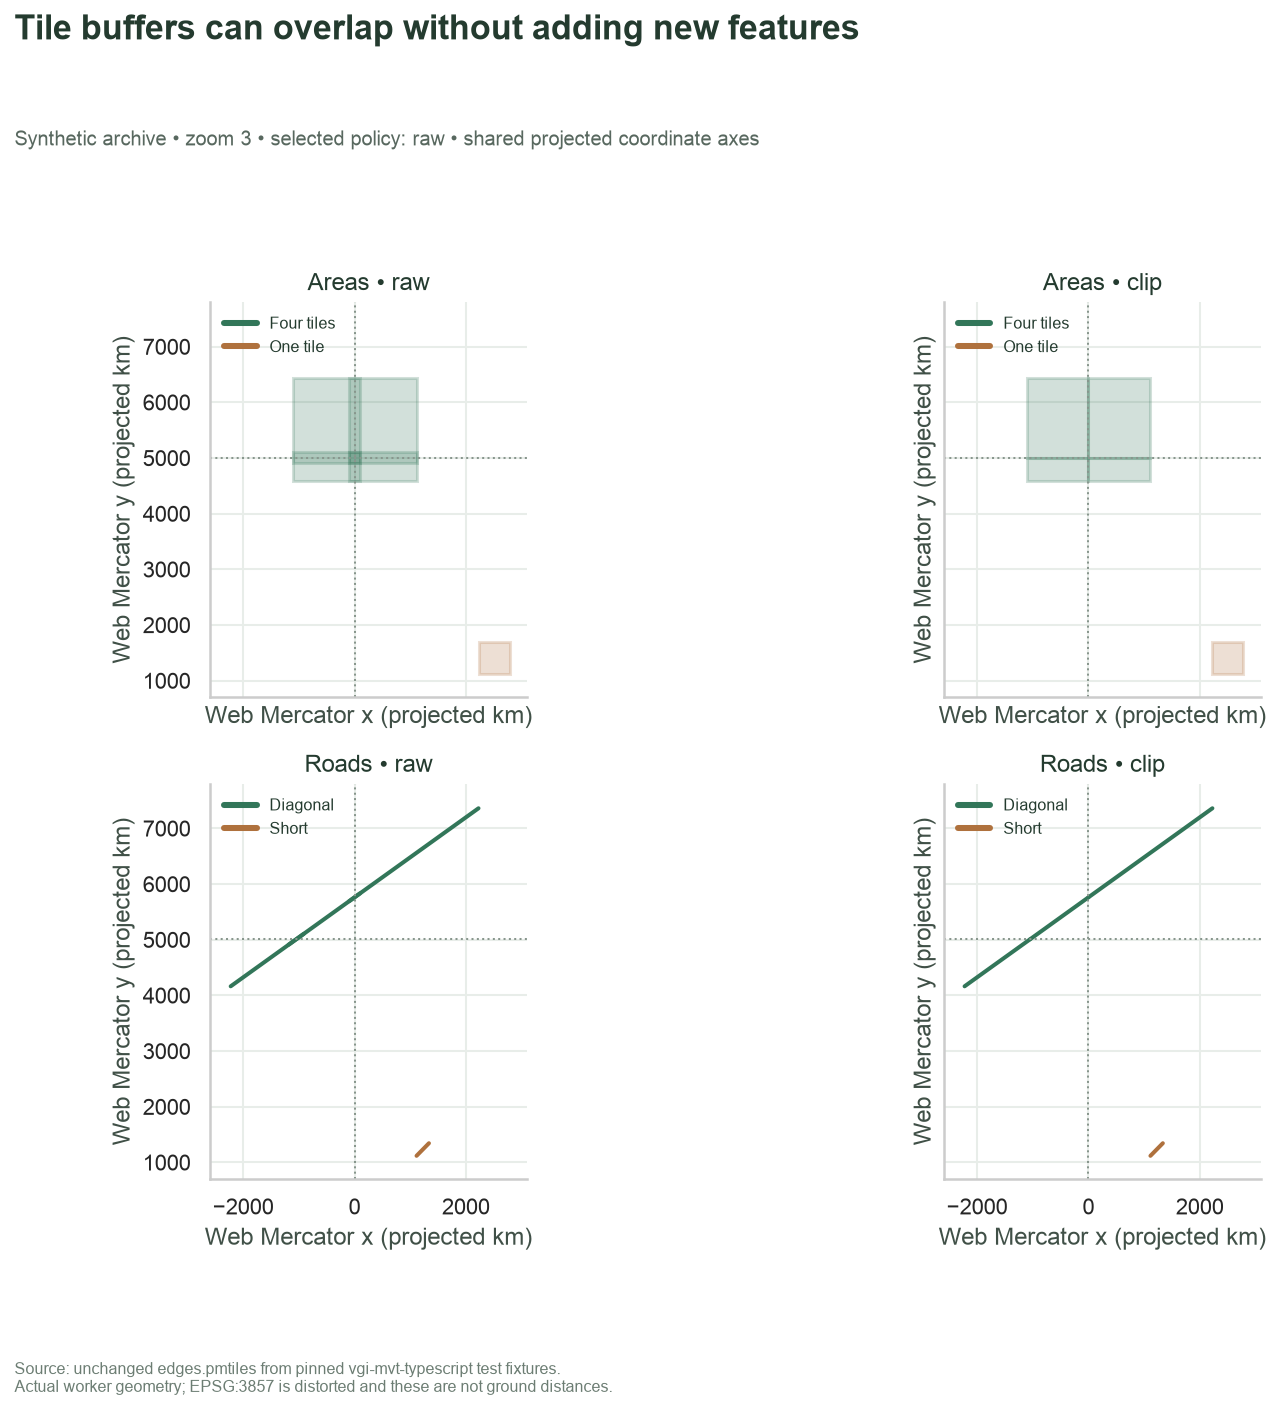

In [9]:
colors={"Four tiles":"#327659","One tile":"#AF713D","Diagonal":"#327659","Short":"#AF713D"}
fig, axes = plt.subplots(2,2,figsize=(11.5,10),sharex=True,sharey=True)
for row, layer in enumerate(["areas","roads"]):
    for col, reading in enumerate(["Selected","Clipped reference"]):
        ax=axes[row,col]
        subset=geometry_frame[(geometry_frame.layer==layer)&(geometry_frame.reading==reading)]
        for item in subset.itertuples():
            draw_geometry(ax,item.geometry_json,colors[item.feature_name])
        ax.axvline(0,color="#88968D",ls=":",lw=1)
        ax.axhline(5009.3770856973,color="#88968D",ls=":",lw=1)
        ax.set(title=f"{layer.title()} • {TILE_EDGES if col==0 else 'clip'}",xlabel="Web Mercator x (projected km)",ylabel="Web Mercator y (projected km)")
        ax.set_aspect("equal",adjustable="box")
        ax.set_xlim(-2600,3100);ax.set_ylim(700,7800)
        for name in subset.feature_name.unique():
            ax.plot([],[],color=colors[name],lw=3,label=name)
        ax.legend(loc="upper left",fontsize=8)
chart(fig,"Tile buffers can overlap without adding new features",
      f"Synthetic archive • zoom 3 • selected policy: {TILE_EDGES} • shared projected coordinate axes",
      "Source: unchanged edges.pmtiles from pinned vgi-mvt-typescript test fixtures.\nActual worker geometry; EPSG:3857 is distorted and these are not ground distances.")

## Compare like units within each layer

Separate panels keep projected area and projected length apart. Each pair uses the same named feature, and the annotation reports the selected reading’s relative difference from clip. Ratios compare edge handling on this fixed archive; they are not a universal buffer correction factor.

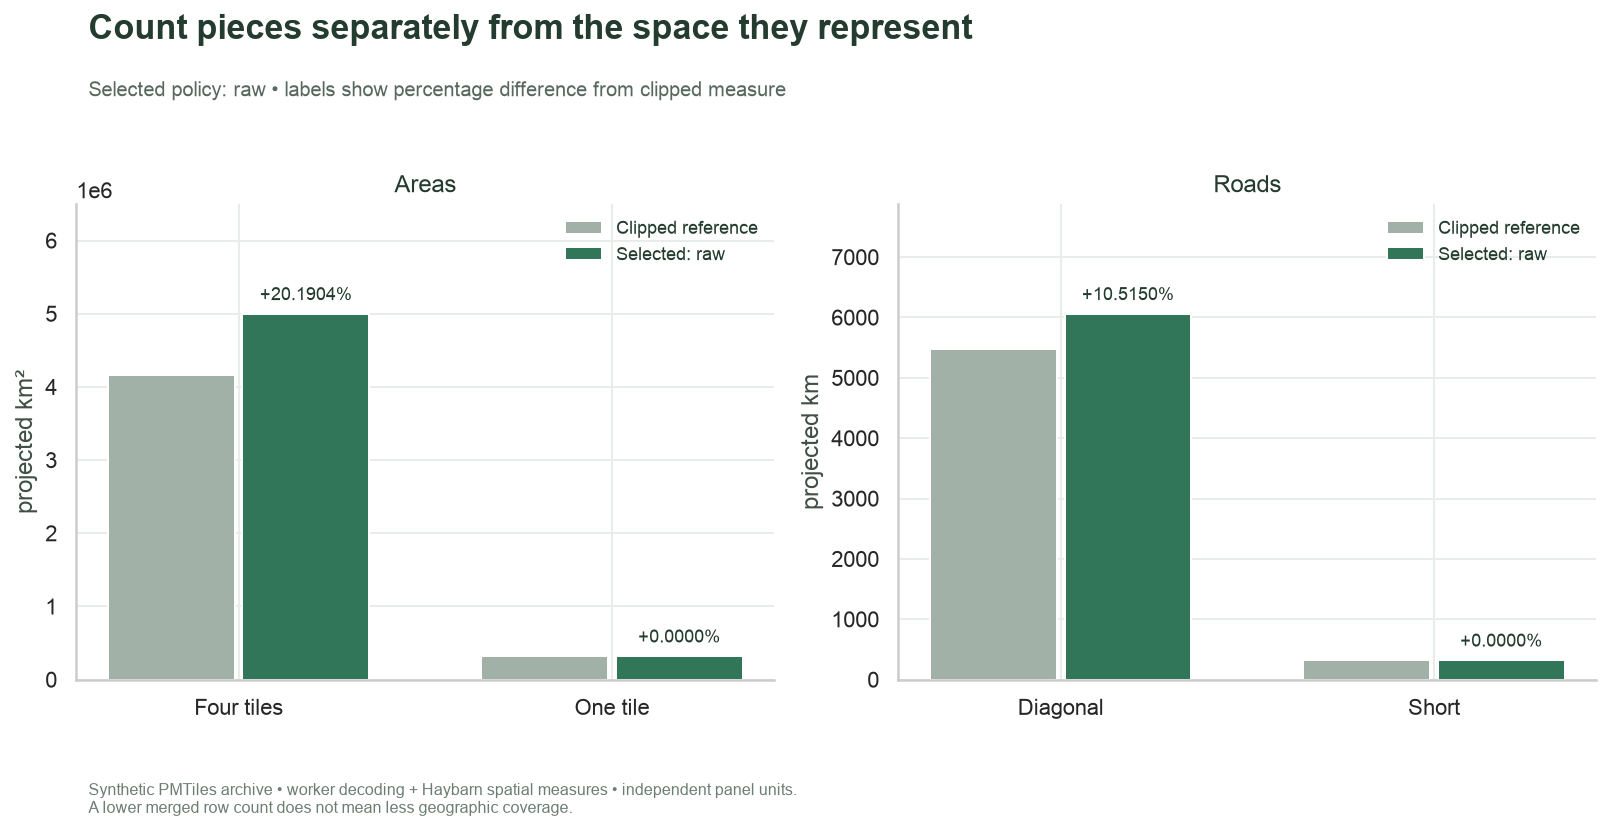

In [10]:
fig, axes = plt.subplots(1,2,figsize=(11.5,5.8))
for ax,layer in zip(axes,["areas","roads"]):
    subset=comparison_frame[comparison_frame.layer==layer].reset_index(drop=True)
    positions=list(range(len(subset)))
    reference=ax.bar([i-.18 for i in positions],subset.clipped_measure,width=.34,color="#A2B1A7",label="Clipped reference")
    selected=ax.bar([i+.18 for i in positions],subset.selected_measure,width=.34,color="#327659",label=f"Selected: {TILE_EDGES}")
    ax.bar_label(selected,labels=[f"{v:+.4f}%" for v in subset.difference_percent],padding=5,fontsize=9)
    ax.set_xticks(positions,subset.feature_name)
    ax.set_ylabel(subset.units.iloc[0]);ax.set_title(layer.title());ax.legend(fontsize=9)
    ax.set_ylim(0,max(subset.clipped_measure.max(),subset.selected_measure.max())*1.30)
chart(fig,"Count pieces separately from the space they represent",
      f"Selected policy: {TILE_EDGES} • labels show percentage difference from clipped measure",
      "Synthetic PMTiles archive • worker decoding + Haybarn spatial measures • independent panel units.\nA lower merged row count does not mean less geographic coverage.")

## Check identities, geometry and policy behavior

These checks reconcile returned geometry and feature keys, verify conversions and validate mode-specific behavior. Merge may slightly alter line length at snapped joins, so its agreement tolerance is **0.1%**, not exact equality. Clipped results are our reference, not the original unquantized GeoJSON. These checks apply to this documented four-feature fixture, not arbitrary archives.

In [11]:
%%sql checks <<
SELECT 'Four unique fixture keys in each reading' AS check_name,
       (SELECT count(*)=8 FROM measurements) AND
       (SELECT count(DISTINCT layer||':'||feature_name)=4 FROM measurements) AS passed
UNION ALL SELECT 'Every paired feature has positive finite measure',
       bool_and(selected_measure>0 AND clipped_measure>0 AND isfinite(selected_measure) AND isfinite(clipped_measure)) FROM comparisons
UNION ALL SELECT 'Every geometry is valid and nonempty', bool_and(ST_IsValid(geometry) AND NOT ST_IsEmpty(geometry)) FROM pieces
UNION ALL SELECT 'Only expected dimensional geometry appears',
       bool_and((layer='roads' AND ST_Dimension(geometry)=1) OR (layer='areas' AND ST_Dimension(geometry)=2)) FROM pieces
UNION ALL SELECT 'Selected piece counts reconcile',
       (SELECT sum(selected_pieces) FROM comparisons)=(SELECT count(*) FROM selected_pieces)
UNION ALL SELECT 'Clipped piece counts reconcile',
       (SELECT sum(clipped_pieces) FROM comparisons)=(SELECT count(*) FROM clipped_pieces)
UNION ALL SELECT 'Metres convert consistently to kilometres',
       abs((SELECT sum(ST_Length(geometry)) FROM selected_pieces WHERE layer='roads')/1000.0-
           (SELECT sum(selected_measure) FROM comparisons WHERE layer='roads'))<1e-8
UNION ALL SELECT 'Raw retains at least clipped measure; other policies agree within 0.1 percent',
       CASE WHEN (SELECT tile_edges FROM settings)='raw' THEN bool_and(difference_percent>=-1e-8)
            ELSE bool_and(abs(difference_percent)<0.1) END FROM comparisons
UNION ALL SELECT 'Merge produces one row per named fixture feature',
       CASE WHEN (SELECT tile_edges FROM settings)='merge' THEN bool_and(selected_pieces=1)
            ELSE bool_and(selected_pieces=clipped_pieces) END FROM comparisons
ORDER BY check_name;

Running query in 'DuckDBPyConnection'

In [12]:
display(checks)
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
prose(f"**All {len(checks)} SQL checks passed.** The observed differences describe edge processing on this archive. "
      "MVT quantization, projection distortion and the choice of feature identity remain separate issues.")

,check_name,passed
0,Clipped piece counts reconcile,True
1,Every geometry is valid and nonempty,True
2,Every paired feature has positive finite measure,True
3,Four unique fixture keys in each reading,True
4,Merge produces one row per named fixture feature,True
5,Metres convert consistently to kilometres,True
6,Only expected dimensional geometry appears,True
7,Raw retains at least clipped measure; other po...,True
8,Selected piece counts reconcile,True


**All 9 SQL checks passed.** The observed differences describe edge processing on this archive. MVT quantization, projection distortion and the choice of feature identity remain separate issues.

## Focused experiment: merge the same stored pieces

Change only `TILE_EDGES` from **"raw"** to **"merge"**, restart and run all. Predict fewer returned pieces and measurements closer to clip, especially for the rectangle spanning four tiles. Compare piece counts, percentage annotations and the first chart’s tile seams. The source archive, zoom, coordinate system and clip reference stay fixed.

A merged row is not a new measurement or proof of real-world accuracy. The experiment isolates the handling of tiled copies; it does not recover the unquantized source or remove Web Mercator distortion. Reset to **"raw"** for the saved default. The runner command in the README saves the experiment separately with its branding, fixtures and instructions.

In [13]:
connection.close()
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>